# Análise Exploratória e Métricas do Modelo

**Sistema Inteligente de Triagem de Diabetes** — Projeto Final CARCDSI
Autores: Emerson Soares da Silva (CG3033741) e Robert Cortez Rudi (CG3035735)

Este notebook reúne as figuras e os números usados no Artigo Científico. Ele não
treina modelos: reutiliza o pré-processamento de `src/preprocess.py` e o modelo
vencedor salvo em `models/best_model.joblib` (gerado por `python -m src.train`),
para que as figuras correspondam exatamente ao sistema entregue.

| Figura | Arquivo em `notebooks/figures/` |
|---|---|
| 1. Distribuição do target | `01_distribuicao_target.png` |
| 2. Matriz de correlação | `02_matriz_correlacao.png` |
| 3. Matriz de confusão | `03_matriz_confusao.png` |
| 4a. SHAP Summary Plot (Pré-diabetes) | `04a_shap_summary_prediabetes.png` |
| 4b. Importância SHAP global por classe | `04b_shap_importancia_global.png` |

Reprodutibilidade: `random_state = 42` em todas as etapas estocásticas.

## 0. Configuração

In [1]:
import json
import logging
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

# Permite importar src/ rodando o notebook a partir de notebooks/ ou da raiz.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.explain import FEATURE_DESCRIPTIONS
from src.preprocess import CLASS_LABELS, RANDOM_STATE, TARGET, clean_and_transform, load_raw_data, split_dataset

logging.basicConfig(level=logging.WARNING)
np.random.seed(RANDOM_STATE)

FIG_DIR = PROJECT_ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DPI = 300

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})

CLASS_COLORS = {0: "#2e7d32", 1: "#f9a825", 2: "#c62828"}
LABELS_PT = {f: FEATURE_DESCRIPTIONS.get(f, f) for f in FEATURE_DESCRIPTIONS}


warnings.filterwarnings("ignore", category=FutureWarning)


def num_pt(v: float, dec: int = 0) -> str:
    # Formata número no padrão brasileiro: 1.234,56
    return f"{v:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def save(fig, name: str) -> None:
    # Salva a figura em PNG (300 dpi) na pasta de figuras do artigo.
    path = FIG_DIR / name
    fig.savefig(path, dpi=DPI)
    print(f"Figura salva em: {path.relative_to(PROJECT_ROOT)}")

## 1. Carga do dataset limpo

O dataset é o **BRFSS 2015** (*Behavioral Risk Factor Surveillance System*), com
253.680 respostas. O pré-processamento de `src/preprocess.py` aplica, nesta ordem:

1. remoção de registros duplicados;
2. descarte de `MentHlth`, `Sex`, `CholCheck`, `AnyHealthcare` e `NoDocbcCost`;
3. criação de `InNaturaFood` (1 se consome frutas **ou** verduras diariamente),
   substituindo `Fruits` e `Veggies`.

O resultado tem 15 variáveis preditoras e o target `Diabetes_012`.

In [2]:
raw = load_raw_data()
df = clean_and_transform(raw)
features = [c for c in df.columns if c != TARGET]

print(f"Registros originais:  {len(raw):,}".replace(",", "."))
print(f"Registros após limpeza: {len(df):,} ({len(raw) - len(df):,} duplicatas removidas)".replace(",", "."))
print(f"Variáveis preditoras: {len(features)}")
df.head()

Registros originais:  253.680
Registros após limpeza: 229.781 (23.899 duplicatas removidas)
Variáveis preditoras: 15


,Diabetes_012,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,HvyAlcoholConsump,GenHlth,PhysHlth,DiffWalk,Age,Education,Income,InNaturaFood
0,0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,5.0,15.0,1.0,9.0,4.0,3.0,1
1,0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,3.0,0.0,0.0,7.0,6.0,1.0,0
2,0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,0.0,5.0,30.0,1.0,9.0,4.0,8.0,1
3,0,1.0,0.0,27.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0,11.0,3.0,6.0,1
4,0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0,11.0,5.0,4.0,1


## 2. Distribuição do target (`Diabetes_012`)

,Classe,Registros,%
0,Sem diabetes,190055,82.71
1,Pré-diabetes,4629,2.01
2,Diabetes,35097,15.27


Figura salva em: notebooks\figures\01_distribuicao_target.png


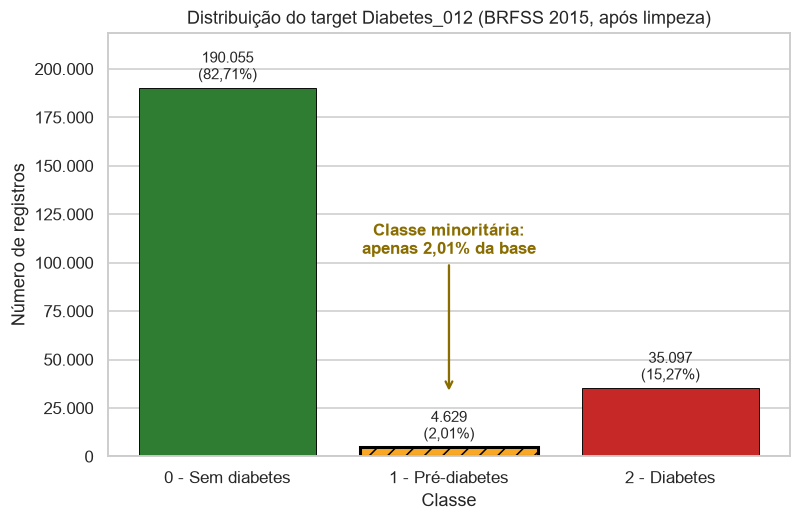

In [3]:
counts = df[TARGET].value_counts().sort_index()
pct = counts / counts.sum() * 100
dist = pd.DataFrame({"Classe": [CLASS_LABELS[c] for c in counts.index], "Registros": counts.values, "%": pct.round(2).values})
display(dist)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    [f"{c} - {CLASS_LABELS[c]}" for c in counts.index],
    counts.values,
    color=[CLASS_COLORS[c] for c in counts.index],
    edgecolor="black", linewidth=0.6,
)
for bar, n, p in zip(bars, counts.values, pct.values):
    ax.annotate(f"{num_pt(n)}\n({num_pt(p, 2)}%)", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=10, xytext=(0, 3), textcoords="offset points")

# Destaque da classe minoritária.
pre = list(counts.index).index(1)
bars[pre].set_hatch("//")
bars[pre].set_linewidth(2)
ax.annotate(
    f"Classe minoritária:\napenas {num_pt(pct.loc[1], 2)}% da base",
    xy=(pre, counts.max() * 0.17), xytext=(pre, counts.max() * 0.55),
    ha="center", fontsize=11, fontweight="bold", color="#8a6d00",
    arrowprops=dict(arrowstyle="->", color="#8a6d00", lw=1.5),
)
ax.set_title("Distribuição do target Diabetes_012 (BRFSS 2015, após limpeza)")
ax.set_xlabel("Classe")
ax.set_ylabel("Número de registros")
ax.set_ylim(0, counts.max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: num_pt(v)))
ax.grid(axis="x", visible=False)
save(fig, "01_distribuicao_target.png")
plt.show()

**Figura 1 — Distribuição do target `Diabetes_012`.** Após a remoção de duplicatas
restam 229.781 registros: 190.055 sem diabetes (82,71%), **4.629 com pré-diabetes
(2,01%)** e 35.097 com diabetes (15,27%). A razão entre a classe majoritária e a de
pré-diabetes é de cerca de 41 para 1.

**Implicação para o artigo.** Com esse desbalanceamento, um classificador que
ignorasse o pré-diabetes ainda teria acurácia acima de 80%. Por isso (i) a divisão
treino/teste é estratificada, (ii) todos os modelos são treinados com pesos
balanceados por classe (`class_weight="balanced"` ou pesos por amostra no XGBoost) e
(iii) a métrica principal é o **Recall e o F1 da Classe 1**, não a acurácia. A
detecção precoce do pré-diabetes é o maior valor clínico de uma triagem, porque essa
fase costuma ser reversível com mudança de hábitos.

## 3. Matriz de correlação entre as 15 variáveis mantidas

Figura salva em: notebooks\figures\02_matriz_correlacao.png


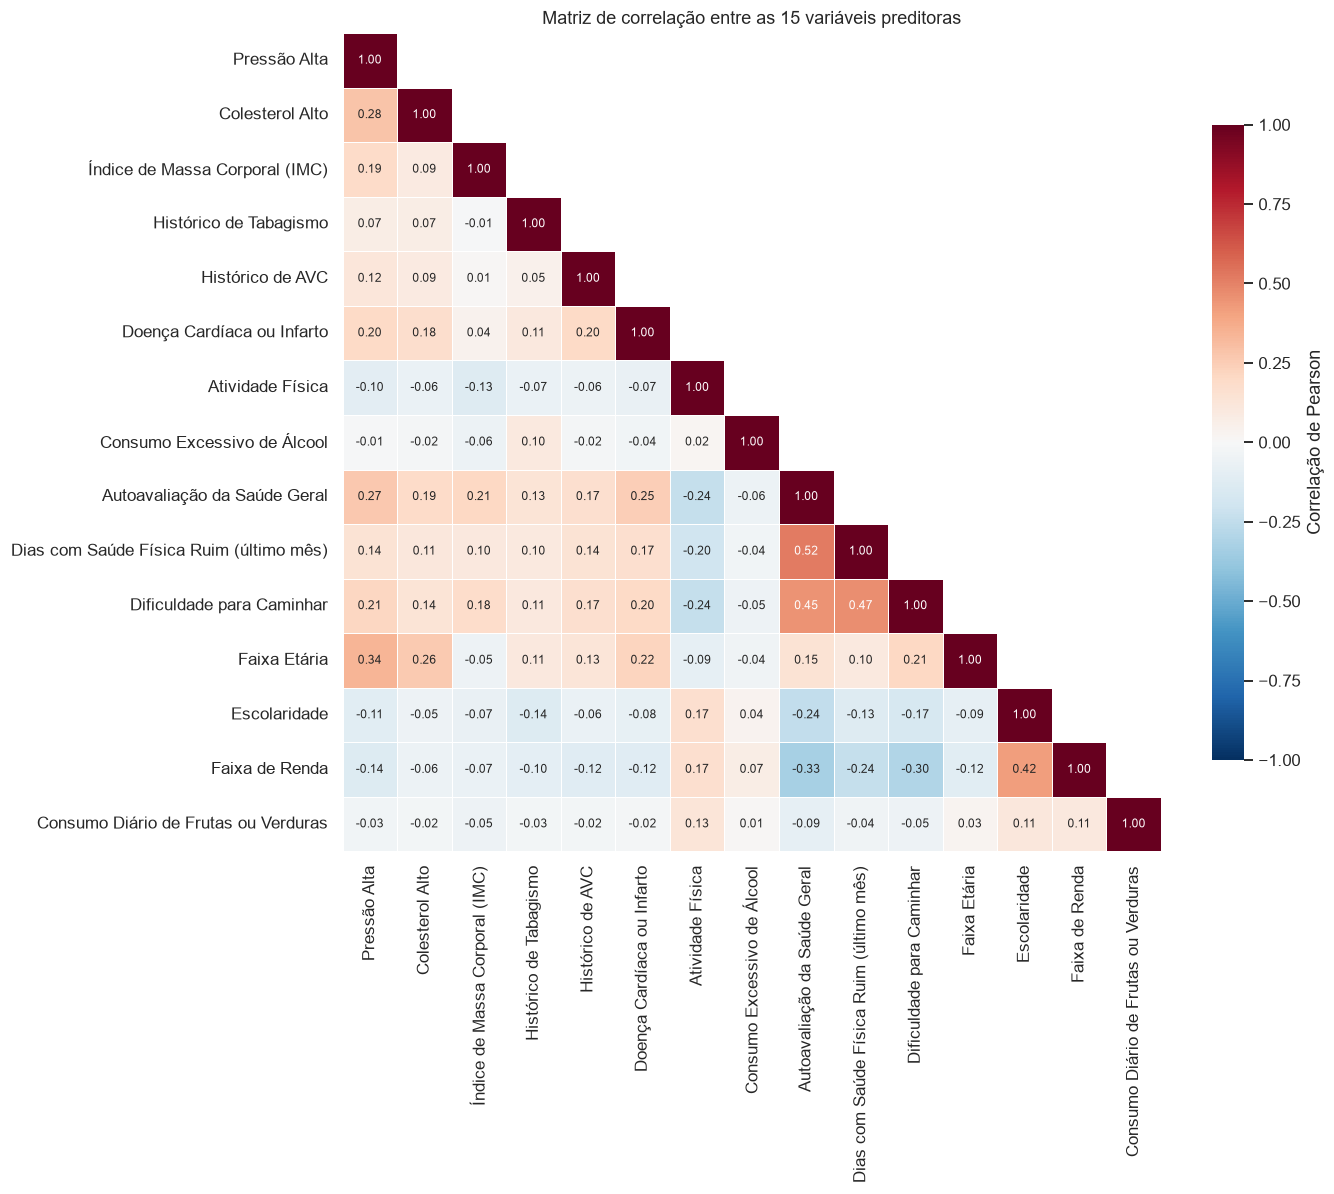

Pares mais correlacionados (|r|):


,,r
GenHlth,PhysHlth,0.517
PhysHlth,DiffWalk,0.467
GenHlth,DiffWalk,0.447
Education,Income,0.419
HighBP,Age,0.340
GenHlth,Income,-0.332


Correlação de cada variável com o target (apoio ao texto, não entra na figura):


,r com Diabetes_012
GenHlth,0.285
HighBP,0.262
BMI,0.212
DiffWalk,0.211
HighChol,0.203
Age,0.185
HeartDiseaseorAttack,0.171
PhysHlth,0.160
Income,-0.147
Education,-0.108


In [4]:
corr = df[features].corr(method="pearson")
corr_pt = corr.rename(index=LABELS_PT, columns=LABELS_PT)

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_pt, dtype=bool), k=1)
sns.heatmap(corr_pt, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.75, "label": "Correlação de Pearson"},
            annot_kws={"size": 8}, ax=ax)
ax.grid(False)
ax.set_title("Matriz de correlação entre as 15 variáveis preditoras")
save(fig, "02_matriz_correlacao.png")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Pares mais correlacionados (|r|):")
display(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(6).round(3).to_frame("r"))
print("Correlação de cada variável com o target (apoio ao texto, não entra na figura):")
display(df.corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("r com Diabetes_012"))

**Figura 2 — Matriz de correlação de Pearson entre as 15 variáveis preditoras.**
Nenhum par apresenta correlação forte (|r| ≥ 0,7). As maiores associações formam um
bloco coerente de **condição física geral**: Autoavaliação da Saúde Geral × Dias com
Saúde Física Ruim (r = 0,52), Dias com Saúde Física Ruim × Dificuldade para Caminhar
(r = 0,47) e Saúde Geral × Dificuldade para Caminhar (r = 0,45). Escolaridade e Renda
também se associam (r = 0,42), assim como Pressão Alta e Faixa Etária (r = 0,34).

**Implicação para o artigo.** A ausência de multicolinearidade forte justifica manter as
15 variáveis e torna mais confiável a leitura dos coeficientes da Regressão Logística e
dos valores SHAP, cujo `LinearExplainer` supõe variáveis aproximadamente independentes.
Em relação ao target, as maiores correlações são com Saúde Geral (0,29), Pressão Alta
(0,26), IMC (0,21), Dificuldade para Caminhar (0,21), Colesterol Alto (0,20) e Idade
(0,19), coerentes com a literatura sobre fatores de risco do diabetes tipo 2.

## 4. Matriz de confusão do modelo vencedor (Regressão Logística)

Modelo: Regressão Logística | conjunto de teste: 45.957 registros


Figura salva em: notebooks\figures\03_matriz_confusao.png


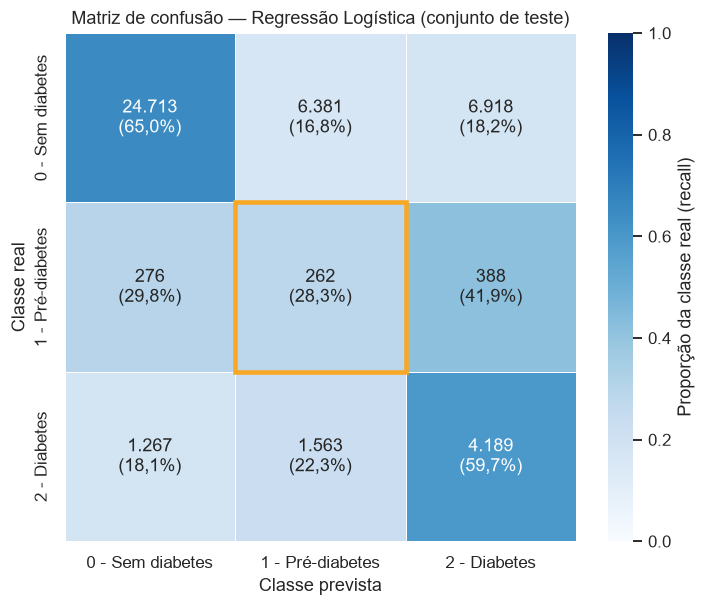

              precision    recall  f1-score   support

Sem diabetes     0.9412    0.6501    0.7691     38012
Pré-diabetes     0.0319    0.2829    0.0574       926
    Diabetes     0.3644    0.5968    0.4525      7019

    accuracy                         0.6346     45957
   macro avg     0.4459    0.5100    0.4263     45957
weighted avg     0.8348    0.6346    0.7064     45957



In [5]:
metrics = json.loads((PROJECT_ROOT / "models" / "metrics.json").read_text(encoding="utf-8"))
model = joblib.load(PROJECT_ROOT / "models" / "best_model.joblib")
data = split_dataset(df)  # mesma divisão estratificada 80/20 do treino (random_state=42)
assert list(data.X_test.columns) == metrics["feature_names"], "Ordem de features diferente da usada no treino."

y_pred = model.predict(data.X_test)
classes = sorted(CLASS_LABELS)
cm = confusion_matrix(data.y_test, y_pred, labels=classes)
assert cm.tolist() == metrics["models"][metrics["best_model"]]["test"]["confusion_matrix"], \
    "Matriz recalculada difere da registrada em metrics.json."
print(f"Modelo: {metrics['best_model']} | conjunto de teste: {len(data.y_test):,} registros".replace(",", "."))

cm_norm = cm / cm.sum(axis=1, keepdims=True)
annot = np.array([[f"{num_pt(cm[i, j])}\n({num_pt(cm_norm[i, j] * 100, 1)}%)" for j in range(3)] for i in range(3)])
names = [f"{c} - {CLASS_LABELS[c]}" for c in classes]

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(cm_norm, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "Proporção da classe real (recall)"},
            xticklabels=names, yticklabels=names, linewidths=0.5, linecolor="white", ax=ax)
ax.grid(False)
ax.add_patch(plt.Rectangle((1, 1), 1, 1, fill=False, edgecolor="#f9a825", lw=3))
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
ax.set_title("Matriz de confusão — Regressão Logística (conjunto de teste)")
save(fig, "03_matriz_confusao.png")
plt.show()

print(classification_report(data.y_test, y_pred, labels=classes, target_names=[CLASS_LABELS[c] for c in classes], digits=4))

In [6]:
# Tabela comparativa dos três modelos (validação cruzada e teste), para a seção de Resultados.
rows = []
for name, m in metrics["models"].items():
    rows.append({
        "Modelo": name + (" *" if name == metrics["best_model"] else ""),
        "CV score de seleção": m["cv"]["selection_score_mean"],
        "Acurácia": m["test"]["accuracy"],
        "F1 Macro": m["test"]["f1_macro"],
        "F1 Weighted": m["test"]["f1_weighted"],
        "Recall Pré-diabetes": m["test"]["recall_class1"],
        "F1 Pré-diabetes": m["test"]["f1_class1"],
    })
pd.DataFrame(rows).sort_values("CV score de seleção", ascending=False).set_index("Modelo").round(4)

,CV score de seleção,Acurácia,F1 Macro,F1 Weighted,Recall Pré-diabetes,F1 Pré-diabetes
Modelo,,,,,,
Regressão Logística *,0.3416,0.6346,0.4263,0.7064,0.2829,0.0574
XGBoost,0.2981,0.6278,0.4222,0.6985,0.2505,0.0539
Random Forest,0.2481,0.6522,0.4287,0.7120,0.1911,0.0546


**Figura 3 — Matriz de confusão da Regressão Logística no conjunto de teste**
(45.957 registros, 20% da base, divisão estratificada). Cada célula mostra a contagem
e, entre parênteses, a proporção em relação à classe real; a diagonal é, portanto, o
recall de cada classe. A célula destacada corresponde ao pré-diabetes.

Resultados principais: acurácia de 63,46%, F1 Macro de 0,4263 e F1 Weighted de 0,7064.
O recall é de 65,0% para Sem diabetes, **28,3% para Pré-diabetes** (262 de 926 casos)
e 59,7% para Diabetes. A precisão do pré-diabetes é baixa (3,2%), o que resulta em
F1 de 0,0574 para essa classe.

**Por que a Regressão Logística venceu.** O critério de seleção, definido antes da
avaliação no teste, foi a média harmônica entre F1 Macro e Recall da Classe 1 na
validação cruzada estratificada de 5 dobras. A Regressão Logística obteve o maior score
(0,3416), contra 0,2981 do XGBoost e 0,2481 da Random Forest, por ter o maior recall
de pré-diabetes (0,287 na validação cruzada) com F1 Macro equivalente aos demais.

**Leitura crítica.** O modelo troca precisão por sensibilidade: muitos pacientes sem
diabetes são sinalizados como pré-diabetes ou diabetes (17% e 18% da classe 0,
respectivamente). Para uma ferramenta de **triagem**, esse é o erro menos grave, pois
o encaminhamento leva a um exame confirmatório barato (glicemia de jejum ou HbA1c),
enquanto o falso negativo deixa de identificar um caso reversível. A confusão entre
pré-diabetes e as classes vizinhas também reflete a natureza do BRFSS: os dados são
autodeclarados e não incluem medidas laboratoriais de glicose.

## 5. Importância de atributos (SHAP)

Formato dos valores SHAP: (3000, 15, 3)


Figura salva em: notebooks\figures\04a_shap_summary_prediabetes.png


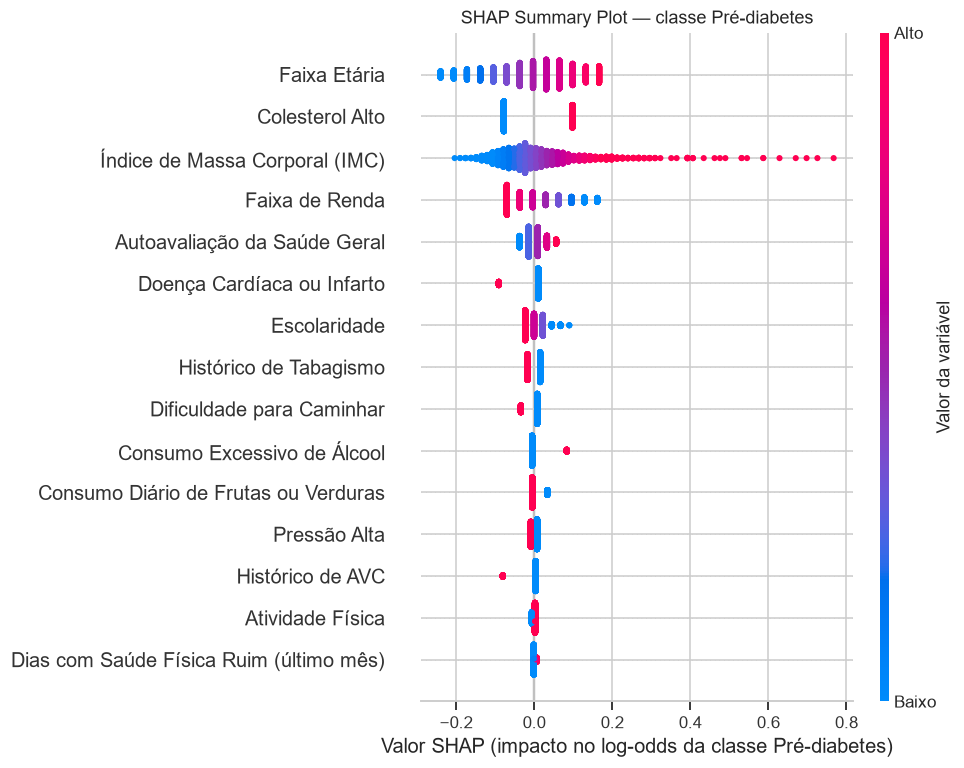

In [7]:
# Mesmo explainer de src/explain.py: LinearExplainer sobre o espaço padronizado,
# com a média do treino (vetor zero após o StandardScaler) como referência.
scaler, clf = model.named_steps["scaler"], model.named_steps["clf"]
n_feat = len(features)
explainer = shap.LinearExplainer(clf, (np.zeros(n_feat), np.eye(n_feat)))

SAMPLE_SIZE = 3000  # amostra do teste: suficiente para o gráfico e rápida de desenhar
sample = data.X_test.sample(SAMPLE_SIZE, random_state=RANDOM_STATE)
sample_scaled = scaler.transform(sample)
shap_values = explainer(sample_scaled).values  # (amostras, variáveis, classes)
print("Formato dos valores SHAP:", shap_values.shape)

feature_names_pt = [LABELS_PT.get(f, f) for f in features]
idx_pre = list(clf.classes_).index(1)

shap.summary_plot(shap_values[:, :, idx_pre], sample_scaled, feature_names=feature_names_pt,
                  show=False, plot_size=(9, 7))
fig = plt.gcf()
fig.axes[0].set_title("SHAP Summary Plot — classe Pré-diabetes")
fig.axes[0].set_xlabel("Valor SHAP (impacto no log-odds da classe Pré-diabetes)")
cbar = fig.axes[-1]
cbar.set_ylabel("Valor da variável")
cbar.set_yticklabels(["Baixo", "Alto"])
save(fig, "04a_shap_summary_prediabetes.png")
plt.show()

Figura salva em: notebooks\figures\04b_shap_importancia_global.png


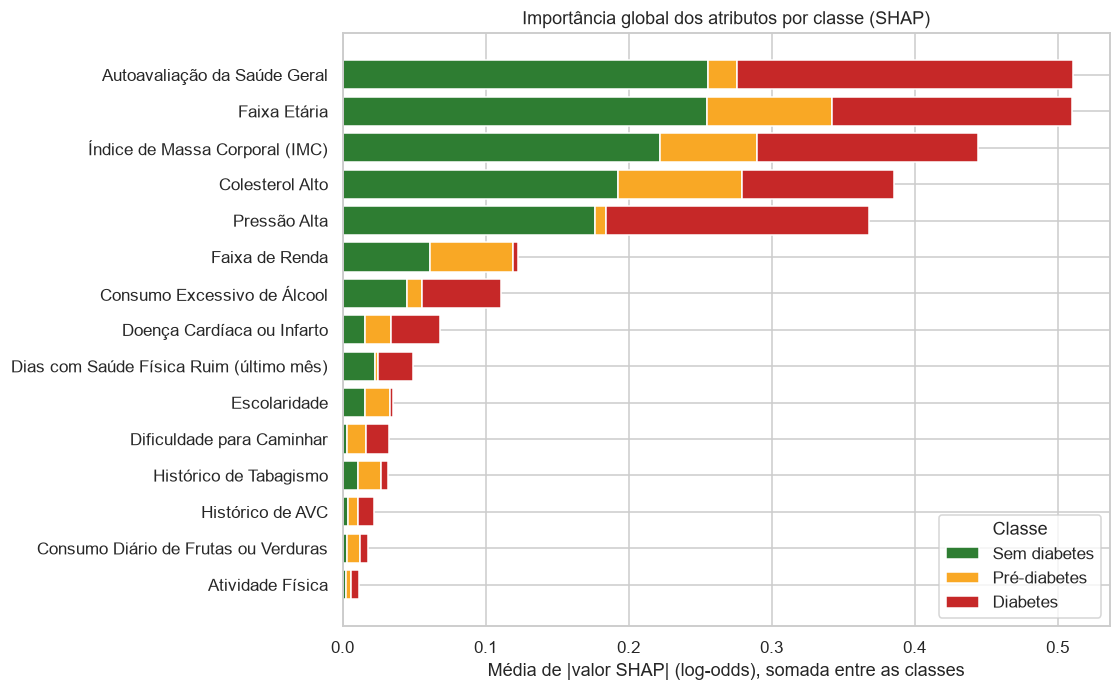

,Sem diabetes,Pré-diabetes,Diabetes,Total
Autoavaliação da Saúde Geral,0.255,0.020,0.235,0.511
Faixa Etária,0.255,0.087,0.168,0.510
Índice de Massa Corporal (IMC),0.222,0.068,0.154,0.444
Colesterol Alto,0.193,0.086,0.106,0.385
Pressão Alta,0.176,0.008,0.184,0.368
Faixa de Renda,0.061,0.058,0.004,0.123
Consumo Excessivo de Álcool,0.045,0.010,0.055,0.111
Doença Cardíaca ou Infarto,0.016,0.018,0.034,0.068
Dias com Saúde Física Ruim (último mês),0.023,0.002,0.025,0.049
Escolaridade,0.015,0.018,0.002,0.036


In [8]:
mean_abs = pd.DataFrame(np.abs(shap_values).mean(axis=0), index=feature_names_pt,
                        columns=[CLASS_LABELS[c] for c in clf.classes_])
mean_abs = mean_abs.loc[mean_abs.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 7))
left = np.zeros(len(mean_abs))
for c in clf.classes_:
    col = CLASS_LABELS[c]
    ax.barh(mean_abs.index, mean_abs[col], left=left, color=CLASS_COLORS[c], label=col, edgecolor="white")
    left += mean_abs[col].values
ax.set_xlabel("Média de |valor SHAP| (log-odds), somada entre as classes")
ax.set_title("Importância global dos atributos por classe (SHAP)")
ax.legend(title="Classe", loc="lower right")
save(fig, "04b_shap_importancia_global.png")
plt.show()

display(mean_abs.assign(Total=mean_abs.sum(axis=1)).sort_values("Total", ascending=False).round(3))

**Figura 4a — SHAP Summary Plot para a classe Pré-diabetes.** Cada ponto é um paciente
de uma amostra de 3.000 registros do conjunto de teste. A posição no eixo horizontal é
o quanto aquela variável empurrou a predição a favor (direita) ou contra (esquerda) o
pré-diabetes; a cor indica o valor da variável (vermelho = alto, azul = baixo, em
escala padronizada). As variáveis estão ordenadas pela importância média para essa classe.

**Figura 4b — Importância global por classe.** Barras empilhadas com a média do valor
absoluto do SHAP de cada variável em cada classe. As cinco variáveis mais influentes no
conjunto são **Autoavaliação da Saúde Geral, Faixa Etária, IMC, Colesterol Alto e
Pressão Alta**, exatamente as classificadas como "muito importantes" na definição do
projeto. Variáveis de hábito e socioeconômicas (Renda, Consumo de Álcool, Doença
Cardíaca) têm peso secundário.

**Implicação para o artigo.** Para o pré-diabetes, os maiores impactos vêm de Faixa
Etária, Colesterol Alto e IMC, seguidos de Faixa de Renda (renda menor empurra para o
pré-diabetes). Com exceção da idade, são fatores modificáveis ou ligados ao acesso a
cuidados, o que reforça o uso da ferramenta para orientar mudanças de hábito. Chama
atenção que Pressão Alta e Saúde Geral, decisivas no conjunto, quase não separam o
pré-diabetes: o modelo as usa principalmente para distinguir **Diabetes** de **Sem
diabetes** (Figura 4b), o que ajuda a explicar a confusão entre o pré-diabetes e as
classes vizinhas vista na Figura 3. A explicação SHAP é a
mesma usada pela aplicação (`src/explain.py`) para escolher os 3 fatores mostrados a
cada paciente e repassados à LLM, o que dá rastreabilidade entre a análise global
apresentada aqui e a explicação individual entregue ao usuário.

> Os valores SHAP estão na escala de log-odds da Regressão Logística multinomial, com a
> média do treino como referência. Como o modelo é linear, o SHAP de cada variável é
> `coeficiente × valor padronizado`, e a explicação é exata (não aproximada).

## 6. Limitações a citar no artigo

- **Dados autodeclarados** (BRFSS é uma pesquisa telefônica): diagnóstico, peso e
  altura são relatados pelo próprio respondente, sem confirmação laboratorial.
- **Contexto norte-americano** (EUA, 2015): faixas de renda em dólares e perfil
  populacional diferentes do brasileiro; o modelo não foi validado em dados do Brasil.
- **Baixa precisão no pré-diabetes**: adequada para triagem (prioriza sensibilidade),
  mas inadequada para diagnóstico.
- **Correlação, não causalidade**: SHAP explica o comportamento do modelo, não relações
  causais entre os fatores e a doença.